In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

# Main project directory
project_path = "/content/drive/MyDrive/Formative2_Facial_Recognition"

# Create folders
folders = [
    "images",
    "processed_images",
    "augmented_images",
    "notebooks",
    "models",
    "results"
]

for folder in folders:
    os.makedirs(os.path.join(project_path, folder), exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [3]:
# Import libraries

import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
# Define the image directory

image_path = os.path.join(project_path, "images")

# Supported image formats
valid_extensions = (".jpg", ".jpeg", ".png")

# Store image information
image_data = []

for member_folder in sorted(os.listdir(image_path)):

    member_path = os.path.join(image_path, member_folder)

    if os.path.isdir(member_path):

        for filename in sorted(os.listdir(member_path)):

            if filename.lower().endswith(valid_extensions):

                file_path = os.path.join(member_path, filename)

                try:
                    with Image.open(file_path) as img:

                        image_data.append({
                            "member": member_folder,
                            "filename": filename,
                            "path": file_path,
                            "width": img.width,
                            "height": img.height,
                            "format": img.format,
                            "mode": img.mode
                        })

                except Exception as e:
                    print(f"Could not open {filename}: {e}")

# Create a DataFrame
df = pd.DataFrame(image_data)

print("Image scanning completed!")
print("Total images found:", len(df))

df

Image scanning completed!
Total images found: 12


,member,filename,path,width,height,format,mode
0,Esther,neutral.jpeg,/content/drive/MyDrive/Formative2_Facial_Recog...,923,1280,JPEG,RGB
1,Esther,smiling.jpeg,/content/drive/MyDrive/Formative2_Facial_Recog...,1123,1280,JPEG,RGB
2,Esther,surprised.jpeg,/content/drive/MyDrive/Formative2_Facial_Recog...,1006,1280,JPEG,RGB
3,Laura,neutral.jpeg,/content/drive/MyDrive/Formative2_Facial_Recog...,810,1080,JPEG,RGB
4,Laura,smiling.jpeg,/content/drive/MyDrive/Formative2_Facial_Recog...,810,1080,JPEG,RGB
5,Laura,surprised.jpeg,/content/drive/MyDrive/Formative2_Facial_Recog...,850,1080,JPEG,RGB
6,Rwema,Neutral.jpeg,/content/drive/MyDrive/Formative2_Facial_Recog...,812,1080,JPEG,RGB
7,Rwema,smiling.jpeg,/content/drive/MyDrive/Formative2_Facial_Recog...,812,1080,JPEG,RGB
8,Rwema,surprised.jpeg,/content/drive/MyDrive/Formative2_Facial_Recog...,812,1080,JPEG,RGB
9,Yusuf,neutral.jpeg,/content/drive/MyDrive/Formative2_Facial_Recog...,540,960,JPEG,RGB


In [5]:
image_counts = df.groupby("member").size()

print("Images per member:")
print(image_counts)

print("\nTotal images:", len(df))

Images per member:
member
Esther    3
Laura     3
Rwema     3
Yusuf     3
dtype: int64

Total images: 12


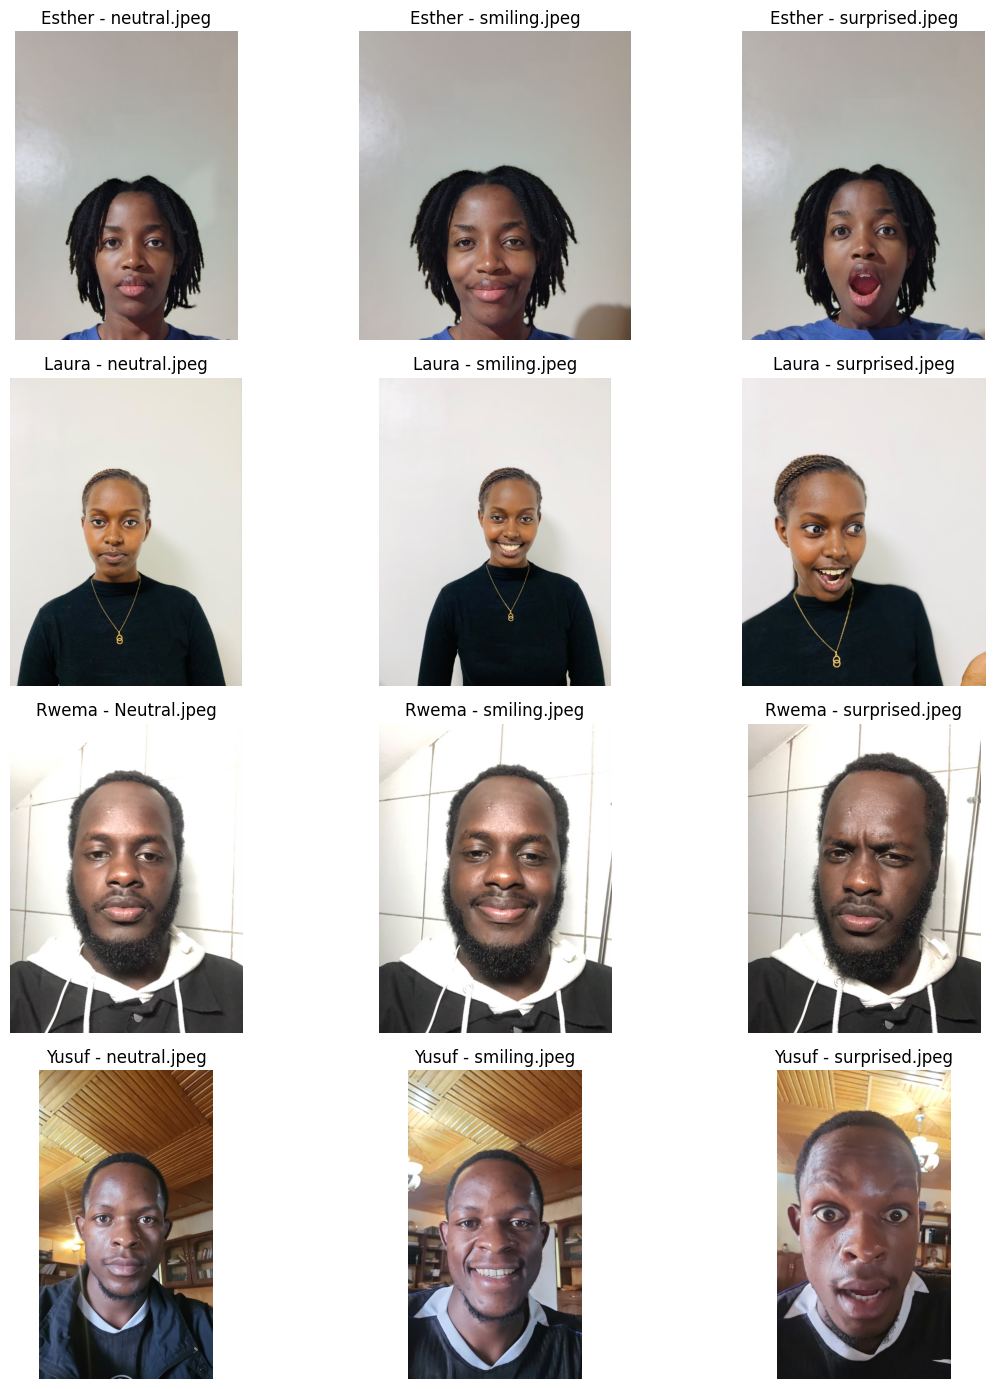

In [6]:
fig, axes = plt.subplots(4, 3, figsize=(12, 14))

for i, (_, row) in enumerate(df.iterrows()):

    ax = axes[i // 3, i % 3]

    with Image.open(row["path"]) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(f'{row["member"]} - {row["filename"]}')
    ax.axis("off")

plt.tight_layout()
plt.show()

In [7]:
print("IMAGE DATASET SUMMARY")
print("--------------------")

print("Total images:", len(df))
print("Unique members:", df["member"].nunique())

print("\nImage dimensions:")
print(df[["width", "height"]].describe())

print("\nImage formats:")
print(df["format"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

IMAGE DATASET SUMMARY
--------------------
Total images: 12
Unique members: 4

Image dimensions:
             width  height
count    12.000000    12.0
mean    798.166667  1100.0
std     182.852565   120.0
min     540.000000   960.0
25%     742.500000  1050.0
50%     812.000000  1080.0
75%     868.250000  1130.0
max    1123.000000  1280.0

Image formats:
format
JPEG    12
Name: count, dtype: int64

Missing values:
member      0
filename    0
path        0
width       0
height      0
format      0
mode        0
dtype: int64


In [8]:

from PIL import Image, ImageOps
import os

# Folder for augmented images
augmented_path = os.path.join(project_path, "augmented_images")

# Count successful augmentations
augmentation_count = 0

for _, row in df.iterrows():

    member = row["member"]
    filename = row["filename"]

    # Create a folder for each member
    member_output_path = os.path.join(augmented_path, member)
    os.makedirs(member_output_path, exist_ok=True)

    # Load the original image
    with Image.open(row["path"]) as img:
        original = img.convert("RGB")

        # 1. Horizontal flip
        flipped = ImageOps.mirror(original)

        # 2. Rotate by 10 degrees
        rotated = original.rotate(
            10,
            resample=Image.Resampling.BICUBIC
        )

        # 3. Convert to grayscale
        grayscale = ImageOps.grayscale(original)

        # Save augmented images
        base_name = os.path.splitext(filename)[0]

        flipped.save(
            os.path.join(member_output_path, f"{base_name}_flipped.jpg")
        )

        rotated.save(
            os.path.join(member_output_path, f"{base_name}_rotated.jpg")
        )

        grayscale.save(
            os.path.join(member_output_path, f"{base_name}_grayscale.jpg")
        )

        augmentation_count += 3

print("IMAGE AUGMENTATION COMPLETED")
print("Original images:", len(df))
print("Augmented images created:", augmentation_count)
print("Total images including originals:", len(df) + augmentation_count)
print("Saved in:", augmented_path)


IMAGE AUGMENTATION COMPLETED
Original images: 12
Augmented images created: 36
Total images including originals: 48
Saved in: /content/drive/MyDrive/Formative2_Facial_Recognition/augmented_images


In [9]:
import numpy as np

feature_records = []

# Define 8 histogram bins for each RGB channel
bins = 8

# Collect original and augmented image paths
all_images = []

# Add original images
for _, row in df.iterrows():
    all_images.append({
        "path": row["path"],
        "member": row["member"],
        "filename": os.path.basename(row["path"]),
        "image_type": "original"
    })

# Add augmented images
for member_folder in os.listdir(augmented_path):
    member_path = os.path.join(augmented_path, member_folder)

    if os.path.isdir(member_path):
        for filename in os.listdir(member_path):
            if filename.lower().endswith((".jpg", ".jpeg", ".png")):
                if "_flipped" in filename:
                    image_type = "flipped"
                elif "_rotated" in filename:
                    image_type = "rotated"
                elif "_grayscale" in filename:
                    image_type = "grayscale"
                else:
                    image_type = "augmented"

                all_images.append({
                    "path": os.path.join(member_path, filename),
                    "member": member_folder,
                    "filename": filename,
                    "image_type": image_type
                })

# Extract RGB histograms
for image_info in all_images:
    image = Image.open(image_info["path"]).convert("RGB")
    image = image.resize((128, 128))

    record = {
        "member": image_info["member"],
        "filename": image_info["filename"],
        "image_type": image_info["image_type"]
    }

    for channel_index, channel_name in enumerate(["R", "G", "B"]):
        histogram, _ = np.histogram(
            np.array(image)[:, :, channel_index],
            bins=bins,
            range=(0, 256)
        )

        # Normalize histogram values
        histogram = histogram / histogram.sum()

        for bin_index, value in enumerate(histogram):
            record[f"{channel_name}_bin_{bin_index}"] = value

    feature_records.append(record)

# Create and save the feature dataset
features_df = pd.DataFrame(feature_records)

features_csv_path = os.path.join(project_path, "image_features.csv")
features_df.to_csv(features_csv_path, index=False)

print("FEATURE EXTRACTION COMPLETED")
print("Images processed:", len(features_df))
print("Feature columns:", len(features_df.columns) - 3)
print("Dataset shape:", features_df.shape)
print("Saved to:", features_csv_path)

FEATURE EXTRACTION COMPLETED
Images processed: 84
Feature columns: 24
Dataset shape: (84, 27)
Saved to: /content/drive/MyDrive/Formative2_Facial_Recognition/image_features.csv


In [10]:
print("ORIGINAL IMAGES:", len(df))

print("\nAUGMENTED IMAGES BY MEMBER:")
for member_folder in sorted(os.listdir(augmented_path)):
    member_path = os.path.join(augmented_path, member_folder)

    if os.path.isdir(member_path):
        image_files = [
            f for f in os.listdir(member_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]
        print(f"{member_folder}: {len(image_files)}")

print("\nFEATURE CSV IMAGES BY TYPE:")
print(features_df["image_type"].value_counts())

print("\nTOTAL IMAGE FILES IN AUGMENTED FOLDER:")
print(sum(
    len([
        f for f in os.listdir(os.path.join(augmented_path, folder))
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])
    for folder in os.listdir(augmented_path)
    if os.path.isdir(os.path.join(augmented_path, folder))
))

ORIGINAL IMAGES: 12

AUGMENTED IMAGES BY MEMBER:
Esther: 18
Laura: 18
Rwema: 18
Yusuf: 18

FEATURE CSV IMAGES BY TYPE:
image_type
augmented    36
original     12
flipped      12
rotated      12
grayscale    12
Name: count, dtype: int64

TOTAL IMAGE FILES IN AUGMENTED FOLDER:
72


In [11]:
# Keep only original images and the three current augmentation types
clean_features_df = features_df[
    features_df["image_type"].isin(
        ["original", "flipped", "rotated", "grayscale"]
    )
].copy()

# Remove duplicate image records, if any
clean_features_df = clean_features_df.drop_duplicates(
    subset=["member", "filename"]
)

# Save the clean feature dataset
clean_csv_path = os.path.join(project_path, "image_features.csv")
clean_features_df.to_csv(clean_csv_path, index=False)

print("CLEAN FEATURE EXTRACTION DATASET")
print("Images:", len(clean_features_df))
print("Feature columns:", len(clean_features_df.columns) - 3)
print("Dataset shape:", clean_features_df.shape)
print("\nImages by type:")
print(clean_features_df["image_type"].value_counts())
print("\nSaved to:", clean_csv_path)

CLEAN FEATURE EXTRACTION DATASET
Images: 48
Feature columns: 24
Dataset shape: (48, 27)

Images by type:
image_type
original     12
flipped      12
rotated      12
grayscale    12
Name: count, dtype: int64

Saved to: /content/drive/MyDrive/Formative2_Facial_Recognition/image_features.csv


In [12]:
# Load the saved CSV file
verified_df = pd.read_csv(clean_csv_path)

print("CSV VERIFICATION")
print("File exists:", os.path.exists(clean_csv_path))
print("Rows:", len(verified_df))
print("Columns:", len(verified_df.columns))
print("\nFirst 5 records:")
print(verified_df.head())

CSV VERIFICATION
File exists: True
Rows: 48
Columns: 27

First 5 records:
   member        filename image_type   R_bin_0   R_bin_1   R_bin_2   R_bin_3  \
0  Esther    neutral.jpeg   original  0.084534  0.039551  0.037415  0.032104   
1  Esther    smiling.jpeg   original  0.092896  0.031433  0.033997  0.041138   
2  Esther  surprised.jpeg   original  0.107849  0.041077  0.052185  0.038452   
3   Laura    neutral.jpeg   original  0.242615  0.007019  0.010498  0.018005   
4   Laura    smiling.jpeg   original  0.247864  0.008179  0.010681  0.015503   

    R_bin_4   R_bin_5   R_bin_6  ...   G_bin_6   G_bin_7   B_bin_0   B_bin_1  \
0  0.041626  0.622681  0.142090  ...  0.118713  0.000000  0.084106  0.082642   
1  0.054932  0.649292  0.096191  ...  0.066467  0.000000  0.085876  0.078491   
2  0.037109  0.610168  0.113037  ...  0.109192  0.000244  0.099670  0.079041   
3  0.020996  0.028015  0.068665  ...  0.059998  0.593567  0.193054  0.079102   
4  0.019470  0.028748  0.084106  ...  0.08880